In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer

df = pd.read_csv("../data/diabetes_binary_classification_data.csv")

# Step 3 - Create TRAIN and TEST
- Split X and y into TRAIN and TEST.
- Use stratify=y so that TRAIN and TEST have approximately the same proportion of class 0 and class 1.
- Keep TEST separate until evaluation. Do not balance or resample TEST.


In [2]:
x = df.drop(columns=['Diabetes_binary'])
y = df['Diabetes_binary']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)


# Step 4 - Prepare the features
Prepare the input features using the information in the Understanding the Dataset guide and the preprocessing methods introduced
in the course. Your preprocessing choice should reflect whether a feature is numerical, binary categorical, or ordered categorical.
Briefly justify how you represent each type. There are no missing values in this dataset, so missing-value imputation is not
required.
- Use a Pipeline/ColumnTransformer where appropriate.
- Anything learned from the data during preprocessing must be learned from TRAIN only and then applied to TEST.


In [3]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]
binary_features = [
    "HighBP", 
    "HighChol", 
    "CholCheck", 
    "Smoker", 
    "Stroke", 
    "HeartDiseaseorAttack", 
    "PhysActivity", 
    "Fruits", 
    "Veggies", 
    "HvyAlcoholConsump", 
    "AnyHealthcare", 
    "NoDocbcCost", 
    "DiffWalk", 
    "Sex"
]
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
])

preprocess = ColumnTransformer(
    [
        ("num", numeric_pipeline, numerical_features),
        ("bin", binary_pipeline, binary_features),
        ("ord", ordinal_pipeline, ordinal_features),
    ],
    remainder="drop"
)

def add_features(X):
    X = X.copy()
    X["ChronicCount"] = (X["HighBP"] + X["HighChol"]
                         + X["Stroke"] + X["HeartDiseaseorAttack"])
    X["LifestyleScore"] = (X["PhysActivity"] + X["Fruits"] + X["Veggies"] 
                           - X["Smoker"] - X["HvyAlcoholConsump"])

    return X
numerical_features += ["ChronicCount", "LifestyleScore"]


**How each feature type is represented:**
- **Numerical** (BMI, MentHlth, PhysHlth): standardised with `StandardScaler`, so features on different scales (BMI ~12–98, days 0–30) are comparable for the Logistic Regression.
- **Binary** (HighBP, Smoker, …): already coded 0/1, so they are not scaled.
- **Ordered categorical** (GenHlth, Age, Education, Income): kept as their ordered integer codes so the model can use the order (e.g. worse health → higher risk), and standardised like the numerical features. One-hot encoding would throw away the order and add many columns.
- **Engineered features:** `ChronicCount` counts the chronic conditions (HighBP, HighChol, Stroke, HeartDiseaseorAttack) and `LifestyleScore` sums healthy habits minus unhealthy ones. Both are treated as numerical.

The median imputers are included as a safeguard, but they have no effect because the dataset has no missing values. All preprocessing is part of the Pipeline, so everything it learns (medians, means, standard deviations) is learned from TRAIN only and then applied to TEST.

# Step 5 - Train Logistic Regression
Use Logistic Regression, as introduced in the classification lecture. Fit the complete Pipeline using TRAIN.
- Use model.predict(X_test) to obtain predicted classes.
- Use model.predict_proba(X_test)[:, 1] to obtain predicted probabilities for class 1.

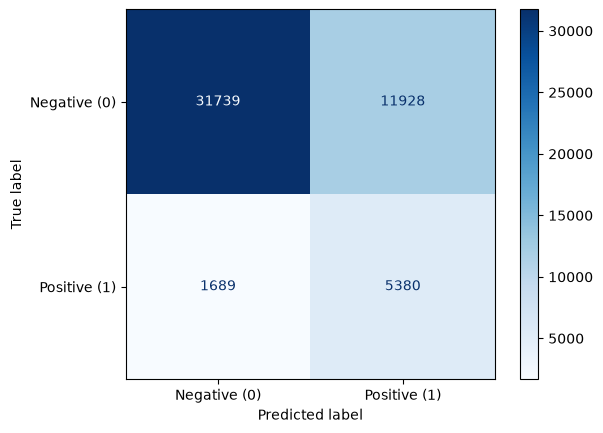

In [4]:
model = Pipeline(steps=[
    ("features", FunctionTransformer(add_features)),
    ("preprocess", preprocess),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

model.fit(x_train, y_train)
y_probs = model.predict_proba(x_test)[:, 1]
threshold = 0.5
y_pred = (y_probs >= threshold).astype(int)

cm = metrics.confusion_matrix(y_test, y_pred)
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative (0)', 'Positive (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.show()

# Step 6 - Evaluate the model
Evaluate the Logistic Regression model on TEST using:
- confusion matrix;
- accuracy;
- precision;
- recall;
- F1 score.

Explain what a false positive and a false negative mean for this diabetes classification problem. Do not judge the model from
accuracy alone.

Accuracy: 0.73
Precission: 0.31
Recall: 0.76
False positive rate: 0.30
True positive rate: 0.63
Area Under the Curve: 0.82
F1: 0.44


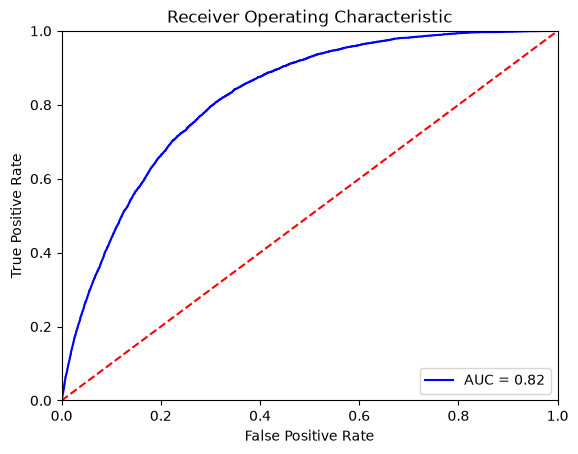

In [5]:
true_negative, false_positive, false_negative, true_positive = cm.ravel()

precission = true_positive / (true_positive + false_positive)
accuracy = (true_positive + true_negative) / (true_negative + false_positive + false_negative + true_positive)
recall = true_positive / (true_positive + false_negative)
print(f"Accuracy: {accuracy:.2f}")
print(f"Precission: {precission:.2f}")
print(f"Recall: {recall:.2f}")

fpr, tpr, threshold = metrics.roc_curve(y_test, y_probs)
roc_auc = metrics.auc(fpr, tpr)
f1 = 2*((precission * recall)/(precission+recall))

print(f"False positive rate: {fpr.mean():.2f}")
print(f"True positive rate: {tpr.mean():.2f}")
print(f"Area Under the Curve: {roc_auc:.2f}")
print(f"F1: {f1:.2f}")

plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

**False positive (FP):** the model predicts diabetes for a person who does not have it. This leads to unnecessary worry and follow-up tests, but a blood test would clear it up.

**False negative (FN):** the model predicts no diabetes for a person who has it. This is usually the more serious error, because the condition can go undiagnosed and untreated.

**What the metrics tell us (threshold 0.50):**
- **Accuracy (0.73):** share of all predictions that are correct.
- **Precision (0.31):** of the people the model flags as diabetic, only about 31 % actually are, so most positive predictions are false alarms.
- **Recall (0.76):** the model finds about 76 % of the people who actually have diabetes.
- **F1 (0.44):** combines precision and recall into one number.
- **ROC-AUC (0.82):** how well the predicted probabilities rank people with diabetes above people without, across all thresholds.

**Why accuracy alone is not enough:** always predicting class 0 gives 0.861 accuracy, which is higher than our model, but it finds nobody with diabetes (recall 0). With an imbalanced target, accuracy is dominated by the large class 0, so precision and recall are needed to see how well class 1 is detected.

# Step 7 - Probability and threshold
Use the predicted probabilities from Logistic Regression to compare two decision thresholds:
- Threshold 0.50
- Threshold 0.40

For each threshold, calculate the confusion matrix, precision and recall. Compare the results. Explain what happened to false
positives, false negatives, precision and recall. Also explain what did NOT change when you changed only the threshold.


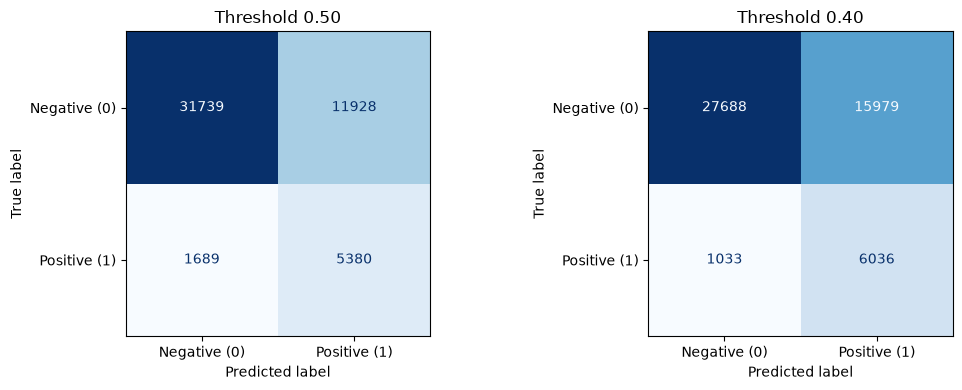

,Accuracy,Precision,Recall,F1,False positives,False negatives
Threshold,,,,,,
0.5,0.732,0.311,0.761,0.441,11928,1689
0.4,0.665,0.274,0.854,0.415,15979,1033


In [6]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for a, t in zip(axes, [0.50, 0.40]):
    y_pred_t = (y_probs >= t).astype(int)
    cm_t = metrics.confusion_matrix(y_test, y_pred_t)
    tn, fp, fn, tp = cm_t.ravel()
    rows.append({
        "Threshold": t,
        "Accuracy": metrics.accuracy_score(y_test, y_pred_t),
        "Precision": metrics.precision_score(y_test, y_pred_t),
        "Recall": metrics.recall_score(y_test, y_pred_t),
        "F1": metrics.f1_score(y_test, y_pred_t),
        "False positives": fp,
        "False negatives": fn,
    })
    metrics.ConfusionMatrixDisplay(cm_t, display_labels=["Negative (0)", "Positive (1)"]).plot(
        ax=a, cmap=plt.cm.Blues, colorbar=False)
    a.set_title(f"Threshold {t:.2f}")
plt.tight_layout()
plt.show()

# Threshold comparison table
pd.DataFrame(rows).set_index("Threshold").round(3)

**What changed.** Lowering the threshold from 0.50 to 0.40 means more people are classified as class 1:
- False positives increased from 11,928 to 15,979.
- False negatives decreased from 1,689 to 1,033.
- Recall increased from 0.761 to 0.854: more people with diabetes are found.
- Precision decreased from 0.311 to 0.274: a larger share of the positive predictions are false alarms.
- Accuracy (0.732 → 0.665) and F1 (0.441 → 0.415) also dropped, since most of the newly flagged people are actually class 0.

**What did not change.** The trained model is the same: the coefficients, the predicted probabilities from `predict_proba` and the ROC-AUC (0.82) are unchanged, and so are the data, the split and the preprocessing. Only the rule that turns probabilities into class labels changed.

# Step 8 - Conclusion
- Summarize the most important things you learned from the EDA and the Logistic Regression results.
- Give at least two limitations of this analysis.
- Do not interpret an association as evidence that one feature causes diabetes.

**What we learned.** The EDA showed that general health, age, high blood pressure, high cholesterol, BMI, difficulty walking and income are the features most strongly associated with diabetes, while several lifestyle features and healthcare access show only weak relationships. These are associations in survey data, not evidence that any feature causes diabetes.

Logistic Regression ranks people reasonably well (ROC-AUC 0.82), but because class 1 is rare it cannot reach both high precision and high recall. The threshold is a trade-off. For screening, a lower threshold such as 0.40 can be preferred because missing a person with diabetes is usually costlier than a false alarm.

**Limitations.**
1. The data is self-reported and cross-sectional, so it can contain reporting errors and only shows associations.
2. Class 1 combines prediabetes and diabetes, and the dataset has 24,206 duplicate rows that can end up in both TRAIN and TEST.
3. Logistic Regression is linear in the log-odds and treats ordered codes such as Age and Income as equally spaced; interactions between features are not modelled.
4. Precision is low (about 0.3), so the model is only suitable as a screening aid, not for diagnosis.
5. Only one train/test split was used, with no cross-validation, and the threshold was not chosen on a separate validation set.